# Footprint Diagram

A footprint diagram shows where rays strike a chosen surface of the system. It answers questions a spot diagram cannot: how large a clear aperture each lens needs, which part of a lens each field uses, and where a beam is clipped. The ray positions are given in the surface's local coordinates, with the origin at its vertex.

In [1]:
from optiland.analysis import FootprintDiagram
from optiland.physical_apertures import RadialAperture
from optiland.samples.objectives import CookeTriplet

In [2]:
lens = CookeTriplet()

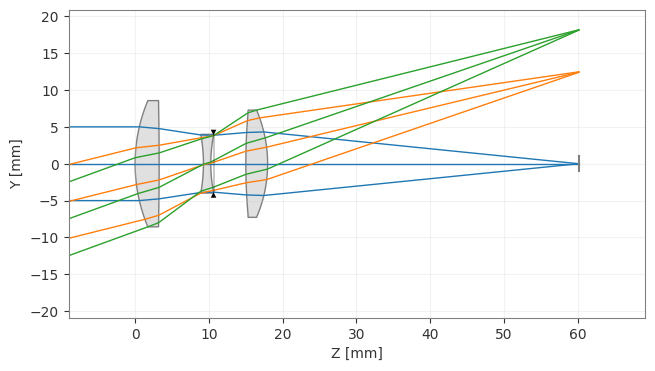

(<Figure size 1000x400 with 1 Axes>, <Axes: xlabel='Z [mm]', ylabel='Y [mm]'>)

In [3]:
lens.draw()

Rays are traced for every field, here at the primary wavelength (pass `wavelengths="all"` for all of them). The first surface of the triplet is far from the stop, so the beams of the three fields land on different parts of it.

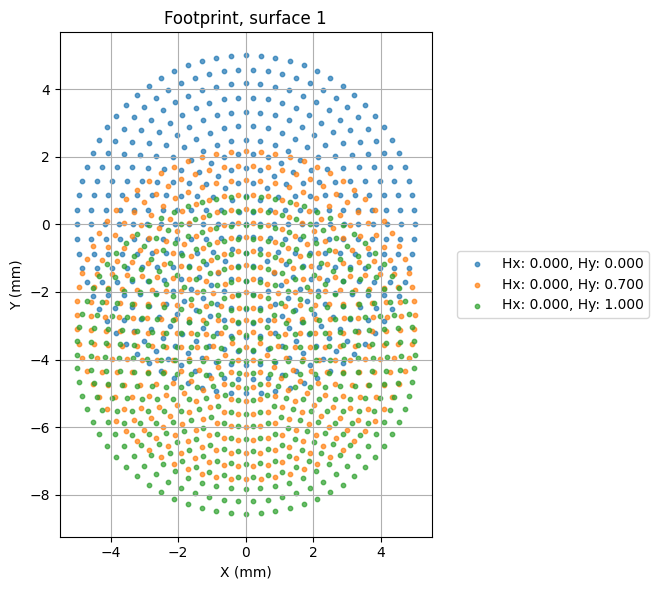

(<Figure size 600x600 with 1 Axes>,
 <Axes: title={'center': 'Footprint, surface 1'}, xlabel='X (mm)', ylabel='Y (mm)'>)

In [4]:
footprint = FootprintDiagram(lens, surface_index=1)
footprint.view()

How to read the plot:

- Each color is one field; the legend gives its normalized field coordinates.
- The beam of the on-axis field is centered on the vertex. Off-axis beams shift away from it, so the edge of the field sets how large the lens must be.
- `extent()` returns the bounding box of all rays that reach the surface, and `max_radius()` the clear semi-aperture they need.

In [5]:
x_min, x_max, y_min, y_max = footprint.extent()
print(f"x: {x_min:.3f} to {x_max:.3f} mm, y: {y_min:.3f} to {y_max:.3f} mm")
print(f"Clear semi-aperture needed: {footprint.max_radius():.3f} mm")

x: -5.000 to 5.000 mm, y: -8.560 to 5.000 mm
Clear semi-aperture needed: 8.560 mm


At the aperture stop every field fills the same circle, whose radius is the marginal ray height at the stop.

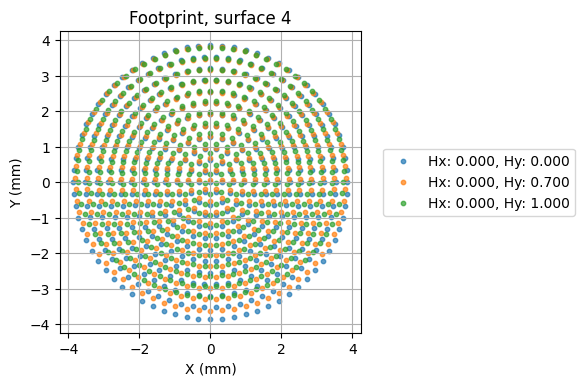

(<Figure size 600x600 with 1 Axes>,
 <Axes: title={'center': 'Footprint, surface 4'}, xlabel='X (mm)', ylabel='Y (mm)'>)

In [6]:
FootprintDiagram(lens, surface_index=lens.surfaces.stop_index).view()

## Clipping

If the surface has a physical aperture, its outline is drawn and the rays it blocks are shown as grey crosses. Here a 7 mm semi-aperture on the first lens surface vignettes the lower part of the full-field beam.

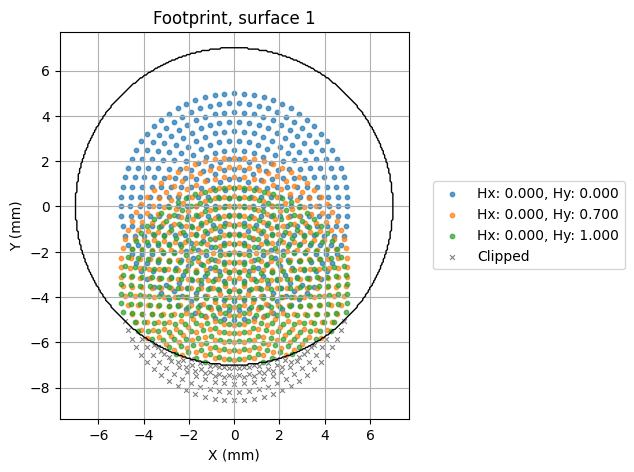

(<Figure size 600x600 with 1 Axes>,
 <Axes: title={'center': 'Footprint, surface 1'}, xlabel='X (mm)', ylabel='Y (mm)'>)

In [7]:
lens.surfaces[1].aperture = RadialAperture(r_max=7.0)
FootprintDiagram(lens, surface_index=1).view()